## Ghi chú MVTec AD
- 15 category, gồm 5 texture và 10 object; 5 category mình dùng đều là object.
- Train chỉ có ảnh tốt; test có cả ảnh lỗi lẫn ảnh tốt; mask chỉ có cho ảnh lỗi trong test.
- Chỉ số đánh giá: Image AUROC, Pixel AUROC và AUPRO
- Quan sát EDA: ảnh good chiếm khoảng 17-39% test; vùng lỗi nhỏ chỉ chiếm ~0.26% pixel (screw/scratch_head).

In [4]:
from pathlib import Path

CATEGORIES = ["bottle", "cable", "capsule", "metal_nut", "screw"]

DATA_ROOT = Path("../data/datasets/mvtec_ad")
print(DATA_ROOT.resolve())
print(DATA_ROOT.exists())

D:\industrial_Visual_Inspection\data\datasets\mvtec_ad
True


In [5]:
for cat in CATEGORIES:
    train_dir = DATA_ROOT / cat / "train" / "good"
    n_train = len(list(train_dir.glob("*.png")))
    print(cat, n_train)

bottle 209
cable 224
capsule 219
metal_nut 220
screw 320


In [6]:
for cat in CATEGORIES:
    test_dir = DATA_ROOT / cat / "test"
    for test_subdir in test_dir.iterdir():
        if test_subdir.is_dir():
            n_test = len(list(test_subdir.glob("*.png")))
            print(f"{cat}/{test_subdir.name}: {n_test}")

bottle/broken_large: 20
bottle/broken_small: 22
bottle/contamination: 21
bottle/good: 20
cable/bent_wire: 13
cable/cable_swap: 12
cable/combined: 11
cable/cut_inner_insulation: 14
cable/cut_outer_insulation: 10
cable/good: 58
cable/missing_cable: 12
cable/missing_wire: 10
cable/poke_insulation: 10
capsule/crack: 23
capsule/faulty_imprint: 22
capsule/good: 23
capsule/poke: 21
capsule/scratch: 23
capsule/squeeze: 20
metal_nut/bent: 25
metal_nut/color: 22
metal_nut/flip: 23
metal_nut/good: 22
metal_nut/scratch: 23
screw/good: 41
screw/manipulated_front: 24
screw/scratch_head: 24
screw/scratch_neck: 25
screw/thread_side: 23
screw/thread_top: 23


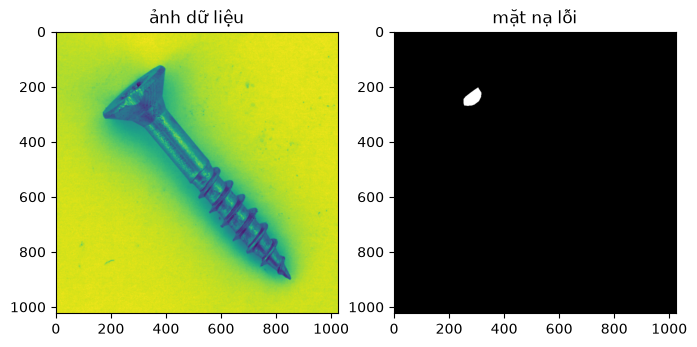

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

cat = "screw"
defect = "scratch_head"

img_path = DATA_ROOT / cat / "test" / defect / "000.png"
mask_path = DATA_ROOT / cat / "ground_truth" / defect / "000_mask.png"

img = Image.open(img_path)
mask = Image.open(mask_path)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img)
axes[0].set_title("ảnh dữ liệu")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("mặt nạ lỗi")
plt.show()

In [8]:
import numpy as np

m = np.array(mask)
print(m.shape, np.unique(m))
print((m > 0).mean())

(1024, 1024) [  0 255]
0.0026388168334960938


## B3: kiểm tra MVTecDataset

In [9]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")
from src.data.mvtec import MVTecDataset, CATEGORIES

for cat in CATEGORIES:
    n_train = len(MVTecDataset("../data/datasets/mvtec_ad", cat, "train"))
    n_test = len(MVTecDataset("../data/datasets/mvtec_ad", cat, "test"))
    print(cat, n_train, n_test)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
bottle 209 83
cable 224 150
capsule 219 132
metal_nut 220 115
screw 320 160


In [10]:
for cat in CATEGORIES:
    samples = MVTecDataset("../data/datasets/mvtec_ad", cat, "test")
    n_with_mask = 0
    n_missing = 0
    for img_path, defect in samples.samples:
        mask_p = samples._mask_path(img_path, defect)
        if mask_p is None:      # ảnh good: không có mask
            continue
        n_with_mask += 1
        if not mask_p.exists():
            n_missing += 1
    print(cat, "có mask:", n_with_mask, "| thiếu mask:", n_missing)

bottle có mask: 63 | thiếu mask: 0
cable có mask: 92 | thiếu mask: 0
capsule có mask: 109 | thiếu mask: 0
metal_nut có mask: 93 | thiếu mask: 0
screw có mask: 119 | thiếu mask: 0


In [12]:
ds = MVTecDataset("../data/datasets/mvtec_ad", "bottle", "test")
for i in [0, len(ds) - 1]:
    image, mask, label, path = ds[i]
    print(image.size, mask.shape, mask.dtype, np.unique(mask), label, path[-40:])

(900, 900) (900, 900) uint8 [0 1] 1 vtec_ad\bottle\test\broken_large\000.png
(900, 900) (900, 900) uint8 [0] 0 tasets\mvtec_ad\bottle\test\good\019.png


In [15]:
ds = MVTecDataset("../data/datasets/mvtec_ad", "bottle", "test")
image, mask, label, path = ds[0]
print(image.shape, image.dtype, mask.shape, mask.dtype, mask.unique(), label)

torch.Size([3, 224, 224]) torch.float32 torch.Size([1, 224, 224]) torch.float32 tensor([0., 1.]) 1


In [21]:
from src.data.mvtec import split_train_calib
from torch.utils.data import Subset

ds = MVTecDataset("../data/datasets/mvtec_ad", "bottle", "train")
tr, ca = split_train_calib(len(ds))
print(len(ds), len(tr), len(ca))
print(set(tr) & set(ca))
print(split_train_calib(len(ds)) == (tr, ca))
print(split_train_calib(len(ds), seed=7)[1] == ca)

209 188 21
set()
True
False


In [22]:
from src.data.mvtec import build_loaders

tr_l, ca_l, te_l = build_loaders("../data/datasets/mvtec_ad", "bottle", batch_size=8)
print(len(tr_l.dataset), len(ca_l.dataset), len(te_l.dataset))
image, mask, label, path = next(iter(te_l))
print(image.shape, mask.shape, label, type(path), len(path))

188 21 83
torch.Size([8, 3, 224, 224]) torch.Size([8, 1, 224, 224]) tensor([1, 1, 1, 1, 1, 1, 1, 1]) <class 'tuple'> 8
